# code_204 · Changing an input record differs from taking an action

**Book:** section 38.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_38_GUIDE.md), [execution evidence](../CHAPTER_38_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_204).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Explanation contracts identify the fitted function, target output, reference population, permitted perturbations and action limits. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8004;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8004


<a id="record-edit-versus-physical-action"></a>
 ## Solve an input-edit problem and audit its meaning
 Generate1,200 source states with positive normalized load q in[2,10], normalized axial stiffness k in[0.6,1.8], and strain proxy q/k with small observation noise. The noisy binary alarm law depends on normalized strain; values are teaching reference units, not field strain magnitudes. Fit source-only StandardScaler and logistic classifier. Explain the fixed physically coherent state q=8,strain=8,k=1. Target model alarm probability at most0.2. In standardized coordinates, solve the closest Euclidean edit to the logistic threshold analytically by projection onto its decision hyperplane. That unconstrained edit can change all three record fields, including stiffness declared immutable for this workflow, and need not satisfy strain=q/k.

 Independently search151 candidate load reductions between2 and8, keeping k=1 and propagating strain=q/k. Choose the largest remaining load whose model probability is at most0.2, making the smallest available grid reduction under this specified action cost. Check immutable stiffness and physical residual for both proposed records. This validates consistency with the declared teaching relation only; it does not estimate causal alarm prevention, engineering feasibility of a real intervention, or authority to perform it. No final label selects the model or target probability.


,state,model_probability,standardized_record_distance,immutable_stiffness_change,physical_relation_residual
Original,"[8.0, 8.0, 1.0]",0.887287,0.0,0.0,0.0
Closest record edit,"[7.071568075339183, 4.268185607961765, 1.14857...",0.2,1.436053,0.148578,-1.888619
Feasible load action,"[4.68, 4.68, 1.0]",0.194343,1.827368,0.0,0.0


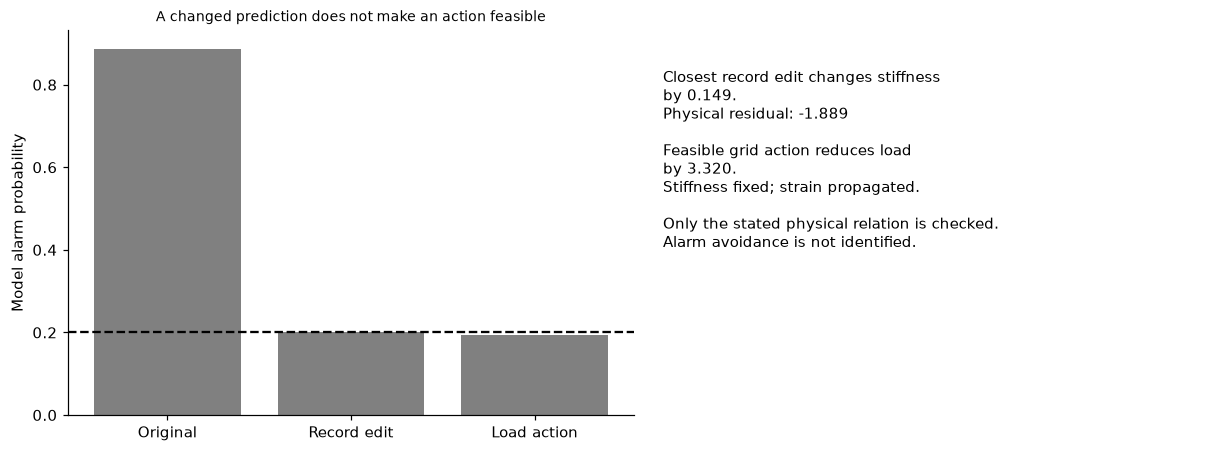

In [2]:
import math
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
load=rng.uniform(2,10,1200);stiffness=rng.uniform(.6,1.8,1200);strain=load/stiffness+rng.normal(scale=.1,size=1200);xs=np.c_[load,strain,stiffness];ys=rng.binomial(1,expit(1.2*(strain-6)));scaler=StandardScaler().fit(xs);model=LogisticRegression(C=2,max_iter=500).fit(scaler.transform(xs),ys)
def probability(x):return model.predict_proba(scaler.transform(np.atleast_2d(x)))[:,1]
query=np.array([8.,8.,1.]);target=.2;z=scaler.transform(query[None])[0];w=model.coef_[0];logit=float(model.decision_function(z[None])[0]);target_logit=float(np.log(target/(1-target)));edit_z=z-(logit-target_logit)*w/(w@w);unconstrained=scaler.inverse_transform(edit_z[None])[0];loads=np.linspace(2,8,151);actions=np.c_[loads,loads/query[2],np.full(151,query[2])];pactions=probability(actions);eligible=np.flatnonzero(pactions<=target);assert len(eligible)>0;chosen=int(eligible[-1]);feasible=actions[chosen];assert np.isclose(probability(unconstrained)[0],target,atol=1e-10);assert feasible[2]==query[2] and np.isclose(feasible[1],feasible[0]/feasible[2]);assert abs(unconstrained[2]-query[2])>1e-8
proposals={}
for name,state in [('Original',query),('Closest record edit',unconstrained),('Feasible load action',feasible)]:proposals[name]={'state':state.tolist(),'model_probability':float(probability(state)[0]),'standardized_record_distance':float(np.linalg.norm(scaler.transform(state[None])[0]-z)),'immutable_stiffness_change':float(state[2]-query[2]),'physical_relation_residual':float(state[1]-state[0]/state[2])}
RESULTS.update(source_states=1200,fixed_query=query.tolist(),target_probability=target,proposal_audit=proposals,feasible_load_reduction=float(query[0]-feasible[0]),action_grid_points=151,physical_check_is_not_intervention_effect=True);display(pd.DataFrame(proposals).T);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(3);names=list(proposals);axes[0].bar(xx,[proposals[k]['model_probability'] for k in names],color='.5');axes[0].axhline(target,color='black',linestyle='--');axes[0].set(xticks=xx,xticklabels=['Original','Record edit','Load action'],ylabel='Model alarm probability',title='A changed prediction does not make an action feasible');axes[1].axis('off');axes[1].text(.03,.9,f'Closest record edit changes stiffness\nby {unconstrained[2]-query[2]:.3f}.\nPhysical residual: {unconstrained[1]-unconstrained[0]/unconstrained[2]:.3f}\n\nFeasible grid action reduces load\nby {query[0]-feasible[0]:.3f}.\nStiffness fixed; strain propagated.\n\nOnly the stated physical relation is checked.\nAlarm avoidance is not identified.',va='top',fontsize=10);plt.show()


<a id="one-prediction-three-questions"></a>
 ## Give each explanation its own question
 For this same classifier and query, compute exact three-feature Shapley contributions in probability units using80 fixed source background states and all eight coalitions. Separately compute load partial dependence by replacing load across all source records while holding their strain/stiffness fields fixed; this operation can break the physical relation. Finally plot the load-action path that changes load and strain together at fixed stiffness. Visual A labels these as local comparison, global fitted-response behaviour and feasible declared action. Their curves and bars are actual evaluations of the fitted model. Additivity, a smooth global curve and a successful physical equation check answer different questions; none alone establishes a real intervention benefit.


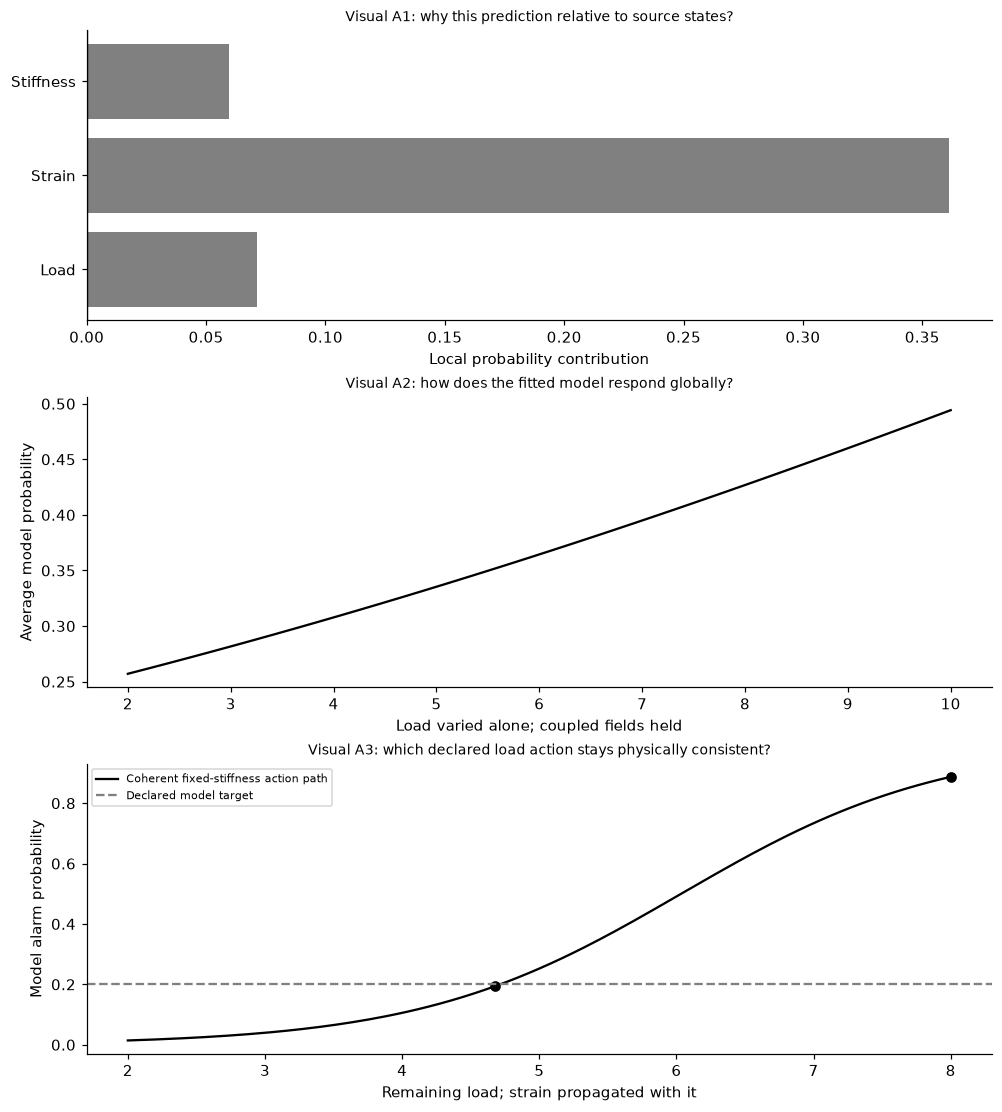

In [3]:
background=xs[:80];values={}
for mask in range(8):
    altered=background.copy()
    for j in range(3):
        if mask&(1<<j):altered[:,j]=query[j]
    values[mask]=float(probability(altered).mean())
phi=np.zeros(3)
for j in range(3):
    for mask in range(8):
        if not mask&(1<<j):
            size=mask.bit_count();phi[j]+=math.factorial(size)*math.factorial(2-size)/6*(values[mask|(1<<j)]-values[mask])
grid=np.linspace(2,10,40);pdp=[]
for q in grid:altered=xs.copy();altered[:,0]=q;pdp.append(float(probability(altered).mean()))
assert np.isclose(values[0]+phi.sum(),probability(query)[0]);assert values[7]==float(probability(np.repeat(query[None],80,axis=0)).mean());assert probability(feasible)[0]<=target;RESULTS.update(local_probability_baseline=values[0],local_probability_contributions=phi.tolist(),global_load_PDP_grid=grid.tolist(),global_load_PDP_values=pdp,local_global_action_questions_distinct=True);fig,axes=plt.subplots(3,1,figsize=(9,10));axes[0].barh(np.arange(3),phi,color='.5');axes[0].axvline(0,color='black');axes[0].set(yticks=range(3),yticklabels=['Load','Strain','Stiffness'],xlabel='Local probability contribution',title='Visual A1: why this prediction relative to source states?');axes[1].plot(grid,pdp,color='black');axes[1].set(xlabel='Load varied alone; coupled fields held',ylabel='Average model probability',title='Visual A2: how does the fitted model respond globally?');axes[2].plot(loads,pactions,color='black',label='Coherent fixed-stiffness action path');axes[2].axhline(target,color='.5',linestyle='--',label='Declared model target');axes[2].scatter([feasible[0],query[0]],probability(np.r_[feasible[None],query[None]]),color='black');axes[2].set(xlabel='Remaining load; strain propagated with it',ylabel='Model alarm probability',title='Visual A3: which declared load action stays physically consistent?');axes[2].legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_204','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual source-scaled logistic alarm model on normalized load strain stiffness', 'analytic closest standardized model-changing edit versus immutable physical constraints', 'explicit load-action search propagating strain through a declared elastic relation', 'same-prediction local attribution global effect and feasible-action Visual A'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual source-scaled logistic alarm model on normalized load strain stiffness", "analytic closest standardized model-changing edit versus immutable physical constraints", "explicit load-action search propagating strain through a declared elastic relation", "same-prediction local attribution global effect and feasible-action Visual A"], "elapsed_seconds": 0.338, "example_id": "code_204", "hardware": "Darwin arm64 CPU", "results": {"action_grid_points": 151, "feasible_load_reduction": 3.3200000000000003, "fixed_query": [8.0, 8.0, 1.0], "global_load_PDP_grid": [2.0, 2.2051282051282053, 2.41025641025641, 2.6153846153846154, 2.8205128205128203, 3.0256410256410255, 3.230769230769231, 3.435897435897436, 3.641025641025641, 3.846153846153846, 4.051282051282051, 4.256410256410256, 4.461538461538462, 4.666666666666666, 4.871794871794872, 5.076923076923077, 5.282051282051282, 5.487179487179487, 5.692307692307692, 5.897435897435898, 6.1025641025641